# Modèles de PD en walk-forward

Deux modèles de PD à 12 mois (régression logistique de référence, gradient boosting challenger) entraînés en walk-forward à fenêtre croissante, puis tableau d'entrée du cœur de validation.

Les choix (millésime, première année de test, 10 classes, seuil de 30 défauts) viennent de `config/freddie_mac.yaml`, fixés avant tout résultat.

In [9]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().parent
sys.path.append(str(RACINE / "src"))

from validation_toolkit.credit.defaults import dates_defaut, marquer_forbearance
from validation_toolkit.credit.panel import construire_panel, resume_panel
from validation_toolkit.credit.models import walk_forward, auc_par_annee, tableau_coeur

INTERIM = RACINE / "data" / "interim"
PROCESSED = RACINE / "data" / "processed"
PROCESSED.mkdir(exist_ok=True)
PROC = Path("../data/processed")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# Valeurs de config/freddie_mac.yaml (decoupe_temporelle, classes_de_risque, seuil_minimal_defauts)
AN = 2007                                  # millésime étudié : 2007 (principal) ou 2015 (réplication)
PREMIERE_ANNEE_TEST = {2007: 2011, 2015: 2019}[AN]
NB_CLASSES = 10
SEUIL = 30
CIBLES = {"principal": "defaut_hors_forbearance", "sensibilite": "defaut"}

## 1. Panel prêt × année

In [11]:
cache = PROCESSED / f"panel_{AN}.pkl"
if cache.exists():
    panel = pd.read_pickle(cache)
else:
    perf, orig = INTERIM / f"perf_{AN}.csv", INTERIM / f"orig_{AN}.csv"
    df_def = marquer_forbearance(perf, dates_defaut(perf))
    panel = construire_panel(orig, perf, df_def, AN)
    panel.to_pickle(cache)

print(f"{len(panel):,} lignes, {panel['id'].nunique():,} prêts, {panel['defaut'].sum():,} défauts")
resume_panel(panel);

289,989 lignes, 49,373 prêts, 2,044 défauts
       prets  defauts  defauts_hors_forbearance    taux
annee                                                  
2016   49373      102                        91  0.0021
2017   44404      241                       142  0.0054
2018   39993      145                       109  0.0036
2019   36337      120                       103  0.0033
2020   31943     1115                        62  0.0349
2021   22450      112                        20  0.0050
2022   15951       66                        29  0.0041
2023   13904       46                        29  0.0033
2024   12876       36                        30  0.0028
2025   11883       42                        29  0.0035
2026   10875       19                        16  0.0017


## 2. Walk-forward : prédictions hors échantillon

Pour prédire l'année *t*, les modèles sont entraînés sur les années strictement antérieures. Cible d'entraînement : `defaut` (règle v2, forbearance incluse).

In [12]:
preds, auc, coeur = {}, {}, {}
for nom, cible in CIBLES.items():
    preds[nom] = walk_forward(panel, PREMIERE_ANNEE_TEST, cible=cible)
    auc[nom] = auc_par_annee(preds[nom], cible=cible)
    coeur[nom] = tableau_coeur(preds[nom], nb_classes=NB_CLASSES)

print(auc["principal"].round(3))

       pd_ref  pd_chall
annee                  
2019    0.803     0.770
2020    0.732     0.714
2021    0.775     0.759
2022    0.708     0.693
2023    0.707     0.660
2024    0.685     0.639
2025    0.620     0.620
2026    0.618     0.720


## 3. Niveau global : PD prédite moyenne contre taux de défaut observé, par année

Résidu = observé − prédit. Un observé au-dessus du prédit signifie que le modèle sous-estime le risque.

,observe,observe_hors_forbearance,pd_ref,pd_chall,biais_ref,biais_chall
annee,,,,,,
2019,0.33,0.28,0.36,0.30,-0.03,0.03
2020,3.49,0.19,0.36,0.35,3.14,3.14
2021,0.50,0.09,0.28,0.20,0.22,0.30
2022,0.41,0.18,0.20,0.09,0.21,0.32
2023,0.33,0.21,0.18,0.24,0.15,0.09
2024,0.28,0.23,0.18,0.27,0.10,0.01
2025,0.35,0.24,0.19,0.25,0.16,0.10
2026,0.17,0.15,0.20,0.14,-0.02,0.04


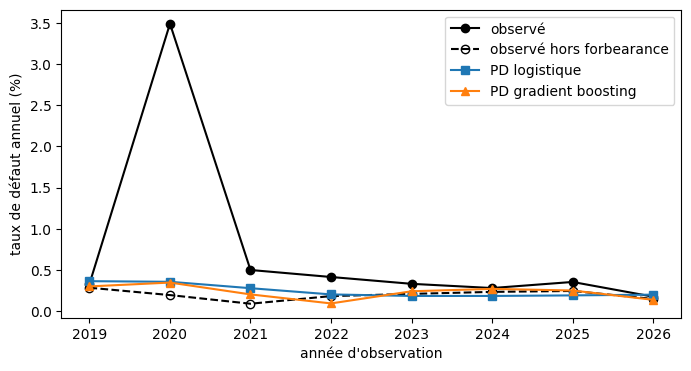

In [13]:
glob = preds["principal"].groupby("annee").agg(observe=("defaut", "mean"),
                                  observe_hors_forbearance=("defaut_hors_forbearance", "mean"),
                                  pd_ref=("pd_ref", "mean"), pd_chall=("pd_chall", "mean"))

glob["biais_ref"] = glob["observe"] - glob["pd_ref"]
glob["biais_chall"] = glob["observe"] - glob["pd_chall"]
display((glob * 100).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(glob.index, glob["observe"] * 100, "k-o", label="observé")
ax.plot(glob.index, glob["observe_hors_forbearance"] * 100, "k--o", mfc="none", label="observé hors forbearance")
ax.plot(glob.index, glob["pd_ref"] * 100, "-s", label="PD logistique")
ax.plot(glob.index, glob["pd_chall"] * 100, "-^", label="PD gradient boosting")
ax.set_xlabel("année d'observation"); ax.set_ylabel("taux de défaut annuel (%)")
ax.legend(); plt.show()

## 4. Tableau d'entrée du cœur, et calibration par classe

Classes = déciles de la PD prédite, recalculés chaque année de test. Une classe est « concluante » si elle cumule au moins 30 défauts sur toute la période de test.

In [14]:
tableau = coeur["principal"]

display(tableau.head(12))

def agreger(d):
    return pd.Series({"n": d["n"].sum(), "n_evenements": d["n_evenements"].sum(),
                      "observe": d["n_evenements"].sum() / d["n"].sum(),
                      "predit": np.average(d["predit"], weights=d["n"])})

par_classe = tableau.groupby(["modele", "groupe"]).apply(agreger, include_groups=False)
par_classe["ecart"] = par_classe["observe"] - par_classe["predit"]
par_classe["concluante"] = par_classe["n_evenements"] >= SEUIL
display(par_classe.round(4))

,date,groupe,modele,observe,predit,n,n_evenements,observe_hors_forbearance,n_evenements_hors_forbearance
0,2019,1,ref,0.000000,0.000267,3633,0,0.000000,0
1,2019,2,ref,0.000000,0.000513,3634,0,0.000000,0
2,2019,3,ref,0.000275,0.000769,3634,1,0.000275,1
3,2019,4,ref,0.001652,0.001070,3633,6,0.001376,5
4,2019,5,ref,0.001376,0.001465,3634,5,0.001376,5
5,2019,6,ref,0.001376,0.001981,3634,5,0.001376,5
6,2019,7,ref,0.003028,0.002724,3633,11,0.003028,11
7,2019,8,ref,0.004128,0.003906,3634,15,0.003577,13
8,2019,9,ref,0.005779,0.006165,3634,21,0.005228,19
9,2019,10,ref,0.015410,0.017448,3634,56,0.012108,44


n  n_evenements  observe  predit   ecart  concluante
modele groupe                                                            
chall  1       15619.0          23.0   0.0015  0.0001  0.0014       False
       2       15622.0          45.0   0.0029  0.0002  0.0027        True
       3       15621.0          74.0   0.0047  0.0004  0.0044        True
       4       15623.0          71.0   0.0045  0.0006  0.0039        True
       5       15622.0         139.0   0.0089  0.0009  0.0080        True
       6       15621.0         148.0   0.0095  0.0013  0.0082        True
       7       15622.0         174.0   0.0111  0.0019  0.0093        True
       8       15622.0         264.0   0.0169  0.0028  0.0141        True
       9       15621.0         270.0   0.0173  0.0046  0.0127        True
       10      15626.0         348.0   0.0223  0.0124  0.0099        True
ref    1       15619.0          21.0   0.0013  0.0002  0.0011       False
       2       15622.0          46.0   0.0029  0.0004  0.0025        True
       3       15621.0          57.0   0.0036  0.0006  0.0030        True
       4       15623.0          68.0   0.0044  0.0009  0.0035        True
       5       15622.0         138.0   0.0088  0.0012  0.0077        True
       6       15621.0         128.0   0.0082  0.0016  0.0066        True
       7       15622.0         206.0   0.0132  0.0022  0.0110        True
       8       15622.0         209.0   0.0134  0.0030  0.0103        True
       9       15621.0         272.0   0.0174  0.0047  0.0127        True
       10      15626.0         411.0   0.0263  0.0129  0.0134        True

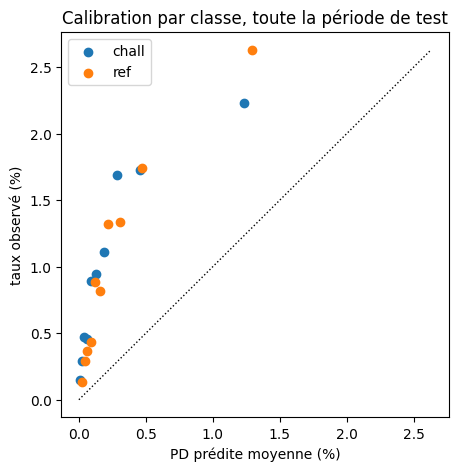

In [15]:
fig, ax = plt.subplots(figsize=(5, 5))
for nom, d in par_classe.groupby("modele"):
    ax.scatter(d["predit"] * 100, d["observe"] * 100, label=nom)
m = par_classe[["predit", "observe"]].max().max() * 100
ax.plot([0, m], [0, m], "k:", lw=1)
ax.set_xlabel("PD prédite moyenne (%)"); ax.set_ylabel("taux observé (%)"); ax.legend()
ax.set_title("Calibration par classe, toute la période de test"); plt.show()

In [16]:
for nom in CIBLES:
    coeur[nom].to_csv(PROC / f"tableau_coeur_{AN}_{nom}.csv", index=False)

**Limites à garder en tête.** Les modèles n'ont ni variable macroéconomique ni l'année en entrée : leur PD ne suit pas le cycle. Le walk-forward entraîne aussi sur les années de forbearance (2020) pour le millésime 2015. Les classes sont recalculées chaque année, donc la composition d'une classe change d'une année à l'autre.